# Lesson 0 · Welcome, Setup & the Forecasting Mindset
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 13** &nbsp;|&nbsp; ⏱ ≈ 45 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Explain what makes time-series data different from ordinary tabular data
> - Set up and verify your Python environment
> - Describe the course roadmap and the final project
> - Run your very first forecast and see why *baselines* matter

**Prerequisites:** Basic Python, NumPy, pandas, and matplotlib (Phases 1–6).

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

## 👋 Welcome

Imagine you are a trader at a produce market. It is Friday evening and you must decide **how many sacks of maize to buy on Monday**.
Buy too many and the price falls, leaving you with unsold stock. Buy too few and you miss out when the price jumps.
Every decision you make depends on one question: **what will the price be next week, next month, next season?**

That is **forecasting**, and the raw material is a **time series**: a sequence of observations ordered in time.
Over the next three weeks you will go from "what is a time series?" to building, comparing and *honestly evaluating* statistical, machine-learning and deep-learning forecasters.

> 💡 **Why this phase matters:** the capstone of your learning path is **agricultural market price prediction**.
> Farmers, traders and governments make million-dollar decisions on these forecasts, which means a forecast that *looks* good but isn't (because of a subtle evaluation mistake) can do real harm.
> Throughout this course we will keep asking: **"Would this still work on data the model has never seen: in the future?"**

## 🗺️ The course map

| Week | Lesson | Notebook | Core idea |
|------|--------|----------|-----------|
| 13 | 0 | `00_Welcome_and_Setup` | Mindset, setup, first forecast |
| 13 | 1 | `01_Time_Series_Fundamentals` | Trend, seasonality, noise, stationarity, ACF/PACF |
| 13 | 2 | `02_Data_Preparation` | Datetime index, resampling, missing data, lags, rolling stats |
| 14 | 3 | `03_Forecast_Evaluation` | MAE/RMSE/MAPE, baselines, walk-forward, horizons |
| 14 | 4 | `04_Statistical_Smoothing` | Moving average, SES, Holt, Holt-Winters |
| 14 | 5 | `05_ARIMA_SARIMA_SARIMAX` | The Box–Jenkins family |
| 15 | 6 | `06_ML_Forecasting` | Lag features + Linear/RF/GBM/XGBoost |
| 15 | 7 | `07_Deep_Learning_Forecasting` | RNN, LSTM, GRU, Transformer |
| 15 | 8 | `08_Practical_Assignment` | The guided 8-step agricultural forecasting experiment |
| 15 | 🏆 | `project/` | Capstone project |

> ❓ *Why is evaluation Lesson 3 and not Lesson 8?* Because you can't judge a model until you know how to *score* one. Evaluation first, models second: just like a driving test comes before a driving licence.

### Each lesson follows the same rhythm
1. **Intuition**: a story or picture before any formula
2. **Worked example**: we do it together, line by line
3. **Your turn**: graded problems 🟢 Easy → 🟡 Medium → 🔴 Challenge, with progressive hints
4. **Recap**: a checklist and "common mistakes" so you know what to remember

## 🔧 Step 1: Check your environment

Run the cell below. Every package should print a version number (no errors).
If something is missing, install everything with `pip install -r requirements.txt` from the course folder.

In [1]:
import importlib
for pkg in ["numpy", "pandas", "matplotlib", "scipy", "statsmodels", "sklearn", "xgboost", "torch"]:
    try:
        m = importlib.import_module(pkg)
        print(f"✅ {pkg:<12} {m.__version__}")
    except Exception as e:
        print(f"❌ {pkg:<12} NOT INSTALLED ({e.__class__.__name__})")

✅ numpy        2.5.4
✅ pandas       3.0.6
✅ matplotlib   3.11.2
✅ scipy        1.18.1
✅ statsmodels  0.15.0


✅ sklearn      1.9.1
✅ xgboost      3.4.1


✅ torch        2.15.0+cu132


> ℹ️ **About PyTorch:** only Lesson 7 (deep learning) needs it. Lessons 0–6 and the practical assignment run without it.
> If your install is slow, skip PyTorch for now and come back later.

## 📦 Step 2: Meet the data

Our main dataset is `data/agri_prices_weekly.csv`: **12 years of weekly wholesale prices** for four commodities, plus weather and fuel data.
It is **simulated** from a transparent recipe (trend + harvest seasonality + rainfall shocks + fuel costs + noise) so you can *know* what structure
your models should find: see `generate_data.py` and `docs/data_dictionary.md`.

| Column | Meaning |
|---|---|
| `date` | Week-ending Sunday |
| `commodity` | maize, tomato, onion, rice |
| `price` | Wholesale price per kg (currency units) |
| `arrivals_tonnes` | Quantity delivered to the market that week |
| `rainfall_mm` | Weekly rainfall in the growing region |
| `temp_c` | Mean temperature |
| `fuel_index` | Transport fuel price index (100 = Jan 2013) |
| `festival_flag` | 1 during the year-end festival weeks |

In [2]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

In [3]:
market = load_weekly()               # all commodities, "long" format
market.head(8)

,date,commodity,price,arrivals_tonnes,rainfall_mm,temp_c,fuel_index,festival_flag
0,2013-01-06,maize,55.39,161.8,23.1,20.9,102.28,1
1,2013-01-13,maize,55.35,167.8,31.4,20.6,104.12,0
2,2013-01-20,maize,55.29,147.7,20.5,21.3,102.19,0
3,2013-01-27,maize,56.81,176.1,18.6,21.2,103.17,0
4,2013-02-03,maize,56.16,136.9,35.6,21.4,105.03,0
5,2013-02-10,maize,56.30,160.5,20.9,22.5,104.54,0
6,2013-02-17,maize,55.11,189.0,29.3,22.8,104.75,0
7,2013-02-24,maize,56.37,175.4,29.0,24.2,102.34,0


In [4]:
maize = load_weekly("maize")         # one commodity, indexed by date
print(maize.shape)
maize.head()

(626, 6)


,price,arrivals_tonnes,rainfall_mm,temp_c,fuel_index,festival_flag
date,,,,,,
2013-01-06,55.39,161.8,23.1,20.9,102.28,1
2013-01-13,55.35,167.8,31.4,20.6,104.12,0
2013-01-20,55.29,147.7,20.5,21.3,102.19,0
2013-01-27,56.81,176.1,18.6,21.2,103.17,0
2013-02-03,56.16,136.9,35.6,21.4,105.03,0


### 👀 Always plot first

> *"The greatest value of a picture is when it forces us to notice what we never expected to see."* by John Tukey

Before reading further, look at the plot and jot down: **Is there a trend? A repeating pattern? Any weird spikes?**

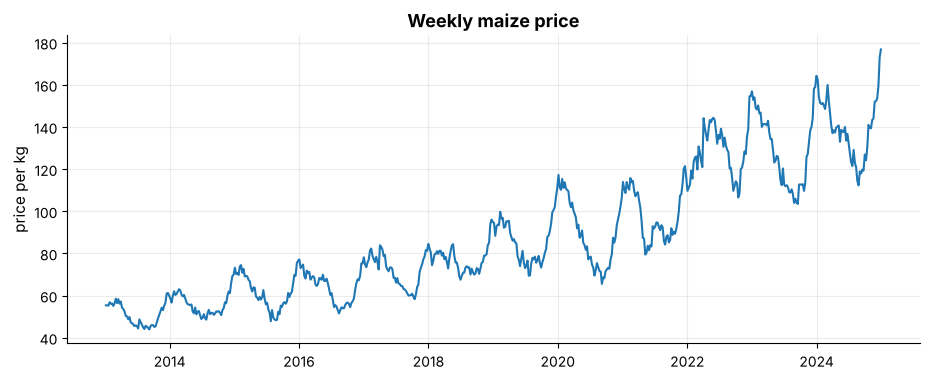

In [5]:
fig, ax = plt.subplots()
ax.plot(maize.index, maize["price"])
ax.set_title("Weekly maize price"); ax.set_ylabel("price per kg"); ax.set_xlabel("")
plt.show()

You probably noticed three things:
- 📈 an upward **trend** (prices roughly tripled),
- 🔁 a yearly **wave** (cheaper after harvest, expensive in the lean season): that is **seasonality**,
- ⚡ irregular wiggles and spikes: **noise** and **shocks** (a drought around 2017 and 2022!).

Lesson 1 formalises these. First, let's meet the single most important difference between time series and everything else you've done so far.

## ⏳ Why time series are different

In earlier phases (regression, classification) we assumed rows were **independent**: shuffle the rows, split randomly, nothing changes.

| Ordinary tabular data | Time-series data |
|---|---|
| Rows are (assumed) independent | Neighbouring rows are **correlated** (today's price ≈ yesterday's) |
| Row order is irrelevant | **Order is the information** |
| Random train/test split is fine | Must split **chronologically**: train on the past, test on the future |
| Future rows may help fill in the past | Using the future to predict the past is **leakage** |

> ⚠️ **The golden rule of this entire course:** *never let the model see the future.*
> Shuffling observations before splitting leaks future information into training and gives gloriously optimistic, and completely fake, scores. We will *prove* this with an experiment in Lesson 3.

## 🎬 Your very first forecast (and a lesson in humility)

Let's forecast the last 26 weeks of maize prices using three ultra-simple ideas.
We hide the last 26 weeks (the **test set**), pretend we are standing at the end of the training data, and ask each method to predict.

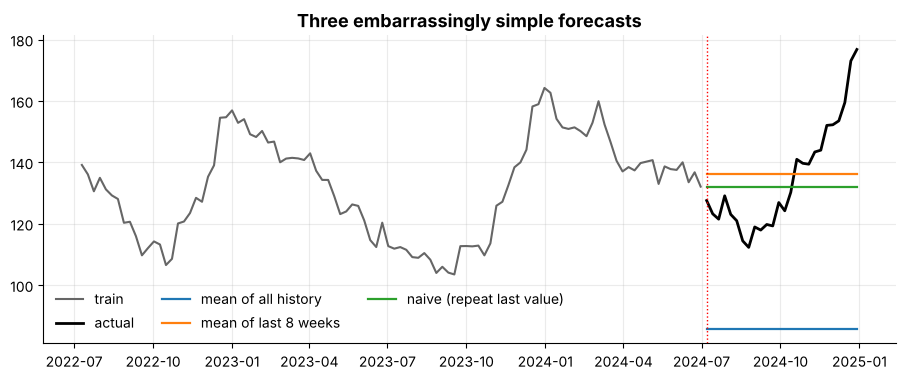

,MAE,RMSE,MAPE,sMAPE
mean of last 8 weeks,14.992,17.456,11.057,10.967
naive (repeat last value),14.364,17.604,10.264,10.496
mean of all history,49.212,52.197,35.537,43.758


In [6]:
h = 26
train, test = maize["price"].iloc[:-h], maize["price"].iloc[-h:]

forecasts = {
    "mean of all history":       np.full(h, train.mean()),
    "mean of last 8 weeks":      np.full(h, train.iloc[-8:].mean()),
    "naive (repeat last value)": np.full(h, train.iloc[-1]),
}
plot_forecasts(train, test, forecasts, "Three embarrassingly simple forecasts")
plt.show()
score_table(test, forecasts)

### 🧠 What just happened?
- The **all-history mean** is terrible: prices trended upward, so the long-run average is far too low.
- The **naive forecast** ("tomorrow = today") is surprisingly hard to beat for prices.
- Our fancy models must beat these **baselines**: otherwise they are not worth their complexity.

> 💡 **Professor's rule:** *Always begin with a baseline.* If a neural network can't beat "repeat the last value", you don't have a deep-learning problem, you have a humility problem.

## 🧩 Practice
These warm-ups use `market` and `maize` from above.

### 🧩 Problem 0.1 · Size up the dataset  ·  🟢 Easy

How many **weeks** of maize prices are in the data, and what are the first and last dates?
  Store the number of rows in `n_weeks`.

<details><summary>💡 Hint 1</summary>

`maize` is a DataFrame. `len(maize)` gives the number of rows.

</details>

<details><summary>💡 Hint 2</summary>

The index holds the dates: `maize.index.min()` and `maize.index.max()`.

</details>

In [7]:
n_weeks = None   # replace None with your answer
check('number of weeks', n_weeks, 626)

⏳ number of weeks: not answered yet (replace the `None` with your answer)


### 🧩 Problem 0.2 · Which crop is the most expensive?  ·  🟢 Easy

Using the full table `market` (all four commodities stacked), compute the **average price per commodity** and
  print them from highest to lowest.

<details><summary>💡 Hint 1</summary>

Use `groupby('commodity')`.

</details>

<details><summary>💡 Hint 2</summary>

After grouping select the `price` column and take `.mean()`; finish with `.sort_values(ascending=False)`.

</details>

In [8]:
# YOUR CODE HERE

### 🧩 Problem 0.3 · Guess before you compute  ·  🟡 Medium

Look at the maize plot above. In **plain words** (write it in a markdown cell or a comment): which months do you think maize is
  cheapest and which are most expensive? Then verify with code: compute the average price for each calendar month of the year
  *after removing the long-run trend* by dividing each price by its 52-week rolling mean.

<details><summary>💡 Hint 1</summary>

`maize['price'].rolling(52, center=True).mean()` is a trend estimate.

</details>

<details><summary>💡 Hint 2</summary>

Ratio = price / trend. Then `groupby(ratio.index.month).mean()`.

</details>

In [9]:
# YOUR PREDICTION (words): 

# YOUR CODE HERE

## ✅ Recap
- A **time series** is a sequence of observations ordered in time; order carries information.
- Neighbouring observations are correlated, so we must **split chronologically** and never shuffle.
- Always compare against simple **baselines** (naive, mean, seasonal naive).
- Your toolkit this phase: **pandas, NumPy, statsmodels, scikit-learn, XGBoost** (+ PyTorch for Lesson 7).

### 🔮 Next lesson
We dissect a time series into **trend, seasonality, cycles and noise**, learn what **stationarity** is, and read **ACF/PACF** plots like a doctor reads an X-ray.